In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    if len(files) > 0 or "images" in root or "labels" in root:
        print(root, "->", len(files), "files")

/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset -> 1 files
/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/valid/labels -> 406 files
/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/valid/images -> 406 files
/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/test/labels -> 406 files
/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/test/images -> 406 files
/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/train/labels -> 3248 files
/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/train/images -> 3248 files


In [2]:
import os
from collections import Counter

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"
class_names = ['helmet', 'no_helmet', 'no_vest', 'person', 'vest']

counts = Counter()
bad_files = 0

for split in ["train", "valid", "test"]:
    split_counts = Counter()
    labels_dir = f"{data_dir}/{split}/labels"
    for fname in os.listdir(labels_dir):
        with open(f"{labels_dir}/{fname}") as f:
            for line in f:
                parts = line.split()
                if not parts:
                    continue
                if len(parts) != 5:      # detection label mein sirf 5 values hoti hain
                    bad_files += 1
                    continue
                name = class_names[int(parts[0])]
                counts[name] += 1
                split_counts[name] += 1
    print(split, dict(split_counts))

print("\nTOTAL:")
for name, c in sorted(counts.items(), key=lambda x: -x[1]):
    print(f"{name}: {c}")
print(f"\nMixed/segment-style lines: {bad_files}")

train {'person': 8259, 'no_helmet': 3993, 'no_vest': 4912, 'helmet': 4068, 'vest': 2952}
valid {'helmet': 531, 'person': 1042, 'vest': 350, 'no_helmet': 523, 'no_vest': 649}
test {'no_helmet': 393, 'no_vest': 513, 'person': 954, 'vest': 396, 'helmet': 529}

TOTAL:
person: 10255
no_vest: 6074
helmet: 5128
no_helmet: 4909
vest: 3698

Mixed/segment-style lines: 0


In [3]:
!pip install pillow -q
import os, random
from PIL import Image, ImageDraw

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"
class_names = ['helmet', 'no_helmet', 'no_vest', 'person', 'vest']
colors = ["#3cb44b", "#e6194b", "#f58231", "#4363d8", "#ffe119"]

split = "train"
images_dir = f"{data_dir}/{split}/images"
labels_dir = f"{data_dir}/{split}/labels"

# Un images ko chunein jinme no_helmet (id=1) ya no_vest (id=2) ho
targets = []
for fname in os.listdir(labels_dir):
    with open(f"{labels_dir}/{fname}") as f:
        ids = {int(l.split()[0]) for l in f if l.strip()}
    if 1 in ids or 2 in ids:
        targets.append(fname)

random.seed(1)
sample = random.sample(targets, 8)

out_dir = "/kaggle/working/tafartech_preview"
os.makedirs(out_dir, exist_ok=True)

for lbl in sample:
    stem = os.path.splitext(lbl)[0]
    img_path = next(f"{images_dir}/{stem}{e}" for e in (".jpg", ".jpeg", ".png") if os.path.exists(f"{images_dir}/{stem}{e}"))
    img = Image.open(img_path).convert("RGB")
    d = ImageDraw.Draw(img)
    w, h = img.size
    for line in open(f"{labels_dir}/{lbl}"):
        if not line.strip():
            continue
        cid, xc, yc, bw, bh = line.split()
        cid = int(cid)
        xc, yc, bw, bh = float(xc)*w, float(yc)*h, float(bw)*w, float(bh)*h
        d.rectangle([xc-bw/2, yc-bh/2, xc+bw/2, yc+bh/2], outline=colors[cid], width=3)
        d.text((xc-bw/2+2, max(0, yc-bh/2-12)), class_names[cid], fill=colors[cid])
    img.save(f"{out_dir}/{stem}.jpg")

print("✅ Saved:", out_dir)

✅ Saved: /kaggle/working/tafartech_preview


In [4]:
import os
import numpy as np

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"
class_names = ['helmet', 'no_helmet', 'no_vest', 'person', 'vest']

sizes = {n: [] for n in class_names}
for fname in os.listdir(f"{data_dir}/train/labels"):
    for line in open(f"{data_dir}/train/labels/{fname}"):
        p = line.split()
        if len(p) == 5:
            sizes[class_names[int(p[0])]].append((float(p[3]), float(p[4])))  # width, height (0-1)

for name, v in sizes.items():
    a = np.array(v)
    print(f"{name:10s} median width={np.median(a[:,0]):.3f}  median height={np.median(a[:,1]):.3f}  median area={np.median(a[:,0]*a[:,1]):.4f}")

helmet     median width=0.067  median height=0.069  median area=0.0048
no_helmet  median width=0.045  median height=0.067  median area=0.0031
no_vest    median width=0.078  median height=0.141  median area=0.0109
person     median width=0.133  median height=0.414  median area=0.0576
vest       median width=0.159  median height=0.266  median area=0.0443


In [5]:
import os
import numpy as np

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"

h_vest, h_novest = [], []
for fname in os.listdir(f"{data_dir}/train/labels"):
    rows = [l.split() for l in open(f"{data_dir}/train/labels/{fname}") if len(l.split()) == 5]
    ids = {int(r[0]) for r in rows}
    persons = [float(r[4]) for r in rows if int(r[0]) == 3]   # person ki height
    if not persons:
        continue
    if 4 in ids and 2 not in ids:      # sirf vest wali images
        h_vest.extend(persons)
    if 2 in ids and 4 not in ids:      # sirf no_vest wali images
        h_novest.extend(persons)

print(f"vest images   : person median height = {np.median(h_vest):.3f}  (n={len(h_vest)})")
print(f"no_vest images: person median height = {np.median(h_novest):.3f}  (n={len(h_novest)})")

vest images   : person median height = 0.681  (n=2305)
no_vest images: person median height = 0.338  (n=4433)


In [6]:
import os

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"

for split in ["train", "valid", "test"]:
    small_vest, big_novest = 0, 0
    for fname in os.listdir(f"{data_dir}/{split}/labels"):
        rows = [l.split() for l in open(f"{data_dir}/{split}/labels/{fname}") if len(l.split()) == 5]
        ids = {int(r[0]) for r in rows}
        heights = [float(r[4]) for r in rows if int(r[0]) == 3]   # person heights
        if 4 in ids and 2 not in ids:
            small_vest += sum(h < 0.35 for h in heights)      # door khade, vest pehne
        if 2 in ids and 4 not in ids:
            big_novest += sum(h > 0.60 for h in heights)      # qareeb khade, vest nahi
    print(f"{split}: door+vest = {small_vest}, qareeb+no_vest = {big_novest}")

train: door+vest = 495, qareeb+no_vest = 1032
valid: door+vest = 21, qareeb+no_vest = 114
test: door+vest = 105, qareeb+no_vest = 101


In [ ]:
!pip install ultralytics -q

In [1]:
import torch
print(torch.cuda.is_available())

True


In [2]:
!pip install kagglehub -q
import kagglehub
path = kagglehub.dataset_download("tafartech/personal-protective-equipmentppe")
print(path)

/kaggle/input/datasets/tafartech/personal-protective-equipmentppe


In [2]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 3.5 MB/s eta 0:00:00


In [3]:
from ultralytics import YOLO

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"

yaml_text = f"""train: {data_dir}/train/images
val: {data_dir}/valid/images
test: {data_dir}/test/images

nc: 5
names: ['helmet', 'no_helmet', 'no_vest', 'person', 'vest']
"""
with open("/kaggle/working/ppe.yaml", "w") as f:
    f.write(yaml_text)

model = YOLO("yolov8n.pt")
results = model.train(
    data="/kaggle/working/ppe.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    scale=0.8,
    project="/kaggle/working/runs",
    name="tafartech_scale08"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/ppe.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freez

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.66G      1.457       1.28      1.369        153        640: 100% ━━━━━━━━━━━━ 203/203 7.2it/s 28.3s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.4it/s 3.0s0.2s
                   all        406       3095      0.742      0.684      0.739      0.376

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.66G      1.499      1.266      1.387        228        640: 100% ━━━━━━━━━━━━ 203/203 7.2it/s 28.4s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.6it/s 2.8s0.2s
                   all        406       3095      0.763      0.639      0.726      0.386

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.66G      1.472       1.23      1.374        312        640: 100% ━━━━━━━━━━━━ 203/203 7.3it/s 27.8s0.1ss
                 Class     Ima

In [4]:
import os

weights_dir = "/kaggle/working/runs/tafartech_scale08/weights"

print(os.listdir(weights_dir))

['best.pt', 'last.pt']


In [2]:
import os
print(os.path.exists("/kaggle/input/datasets/hamanali/bestfile"))

True


In [3]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 2.3 MB/s eta 0:00:00eta 0:00:01


In [4]:
import glob
from ultralytics import YOLO

pts = glob.glob("/kaggle/input/datasets/hamanali/bestfile/**/*.pt", recursive=True)
print("Model files:", pts)
assert pts, "no found file .pt, kindly check again floder"

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"
with open("/kaggle/working/ppe.yaml", "w") as f:
    f.write(f"""train: {data_dir}/train/images
val: {data_dir}/valid/images
test: {data_dir}/test/images

nc: 5
names: ['helmet', 'no_helmet', 'no_vest', 'person', 'vest']
""")

model = YOLO(pts[0])
metrics = model.val(data="/kaggle/working/ppe.yaml", split="test", device="cpu")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model files: ['/kaggle/input/datasets/hamanali/bestfile/best.pt']
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 4.5±2.4 MB/s, size: 50.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/test/labels... 406 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 406/406 142.6it/s 2.8s0.0s
WARNING ⚠️ val: Cach

In [5]:
import os, glob
import numpy as np
from ultralytics import YOLO

data_dir = "/kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset"
img_dir = f"{data_dir}/test/images"
lbl_dir = f"{data_dir}/test/labels"
model = YOLO("/kaggle/input/datasets/hamanali/bestfile/best.pt")

NO_VEST, PERSON, VEST = 2, 3, 4
groups = {"far+vest": [], "near+vest": [], "far+no_vest": [], "near+no_vest": []}

for lbl in os.listdir(lbl_dir):
    rows = [l.split() for l in open(f"{lbl_dir}/{lbl}") if len(l.split()) == 5]
    ids = {int(r[0]) for r in rows}
    hs = [float(r[4]) for r in rows if int(r[0]) == PERSON]
    if not hs:
        continue
    imgs = glob.glob(f"{img_dir}/{os.path.splitext(lbl)[0]}.*")
    if not imgs:
        continue
    med = np.median(hs)
    if VEST in ids and NO_VEST not in ids:
        if med < 0.35: groups["far+vest"].append(imgs[0])
        elif med > 0.60: groups["near+vest"].append(imgs[0])
    elif NO_VEST in ids and VEST not in ids:
        if med < 0.35: groups["far+no_vest"].append(imgs[0])
        elif med > 0.60: groups["near+no_vest"].append(imgs[0])

for name, paths in groups.items():
    if not paths:
        print(f"{name:13s}: 0 images")
        continue
    hits = 0
    for r in model.predict(paths, conf=0.25, device="cpu", verbose=False, stream=True):
        if (r.boxes.cls == NO_VEST).any():
            hits += 1
    print(f"{name:13s}: {len(paths):3d} images, model ne no_vest bola: {hits} ({100*hits/len(paths):.0f}%)")

far+vest     :  38 images, model ne no_vest bola: 9 (24%)
near+vest    :  88 images, model ne no_vest bola: 1 (1%)
far+no_vest  :  66 images, model ne no_vest bola: 62 (94%)
near+no_vest :  50 images, model ne no_vest bola: 49 (98%)


In [6]:
for conf in [0.25, 0.40, 0.50, 0.60]:
    row = []
    for name in ["far+vest", "near+vest", "far+no_vest", "near+no_vest"]:
        paths = groups[name]
        hits = sum(
            bool((r.boxes.cls == NO_VEST).any())
            for r in model.predict(paths, conf=conf, device="cpu", verbose=False, stream=True)
        )
        row.append(f"{name}: {100*hits/len(paths):3.0f}%")
    print(f"conf={conf:.2f} | " + " | ".join(row))

conf=0.25 | far+vest:  24% | near+vest:   1% | far+no_vest:  94% | near+no_vest:  98%
conf=0.40 | far+vest:  16% | near+vest:   1% | far+no_vest:  92% | near+no_vest:  98%
conf=0.50 | far+vest:  11% | near+vest:   1% | far+no_vest:  88% | near+no_vest:  96%
conf=0.60 | far+vest:  11% | near+vest:   1% | far+no_vest:  80% | near+no_vest:  92%


In [9]:
os.makedirs("/kaggle/working/far_vest_false_alarms", exist_ok=True)
results = model.predict(groups["far+vest"], conf=0.25, device="cpu", verbose=False)
for path, r in zip(groups["far+vest"], results):
    if (r.boxes.cls == NO_VEST).any():
        r.save(filename=f"/kaggle/working/far_vest_false_alarms/{os.path.basename(path)}")
        

In [10]:
saved = os.listdir("/kaggle/working/far_vest_false_alarms")
print(len(saved), "images saved")
print(saved[:10])

9 images saved
['0_jpg.rf.ca1f126fcce57f271d260a158f0c40b4.jpg', 'Screenshot-2023-11-08-151018_png_jpg.rf.ab7e41b8969dd79f74349d5258a9cd8f.jpg', 'IMG_2496_PNG_jpg.rf.febc414a94d6fdda16c40930607c946b.jpg', '2008_008320_jpg.rf.08a4779c5cbc862d60908c1a92a0a567.jpg', 'IMG_5846_jpg.rf.ea8c7eabbc61de5b74ae7bb4fc51870e.jpg', 'IMG_2500_PNG_jpg.rf.ca1cdac427fb96241b5031176d5bd121.jpg', 'img_0069_png_jpg.rf.d139967cda66a194e523d1402f134e7b.jpg', 'Aitin2428_jpg.rf.a3a4a16616020ba665dd36e2fdf839a6.jpg', 'r299_jpg.rf.1e10a1a5bdfa0e1412b4c58c9c112416.jpg']


0_jpg.rf.ca1f126fcce57f271d260a158f0c40b4.jpg


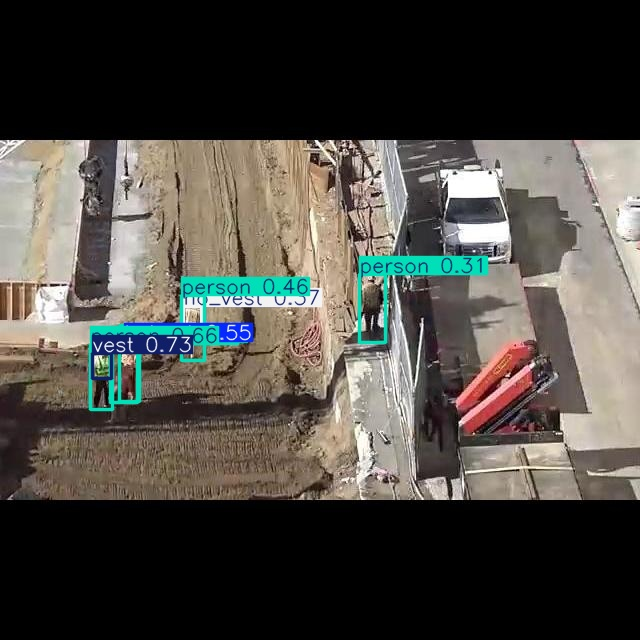

Screenshot-2023-11-08-151018_png_jpg.rf.ab7e41b8969dd79f74349d5258a9cd8f.jpg


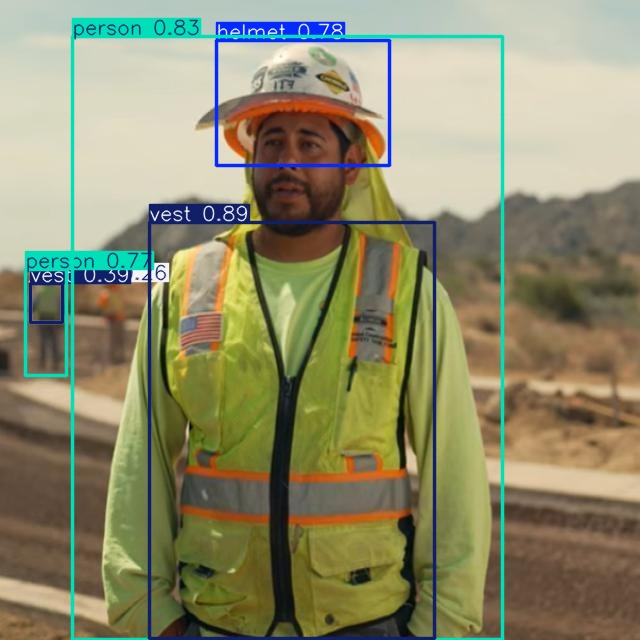

IMG_2496_PNG_jpg.rf.febc414a94d6fdda16c40930607c946b.jpg


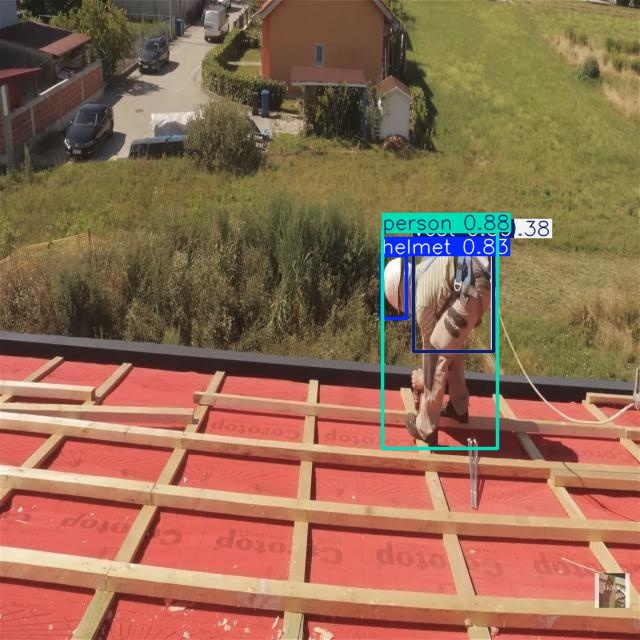

2008_008320_jpg.rf.08a4779c5cbc862d60908c1a92a0a567.jpg


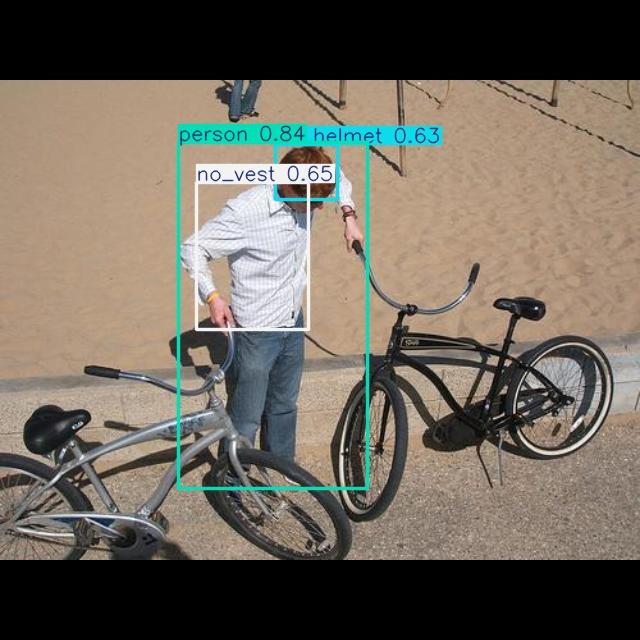

IMG_5846_jpg.rf.ea8c7eabbc61de5b74ae7bb4fc51870e.jpg


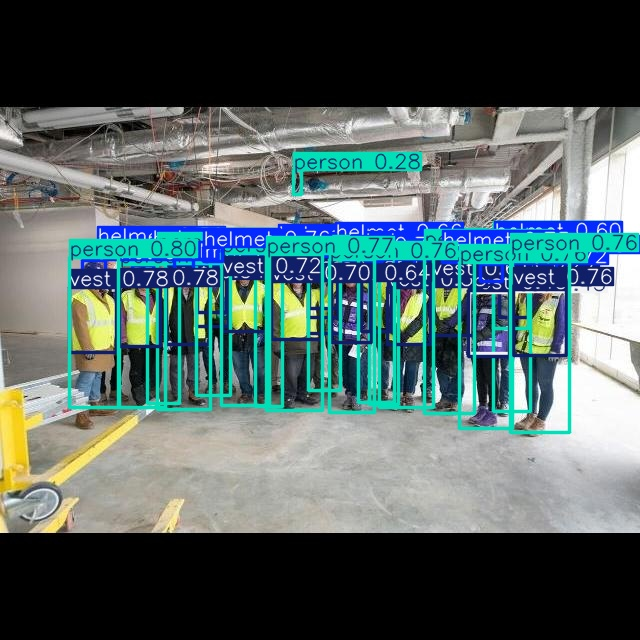

IMG_2500_PNG_jpg.rf.ca1cdac427fb96241b5031176d5bd121.jpg


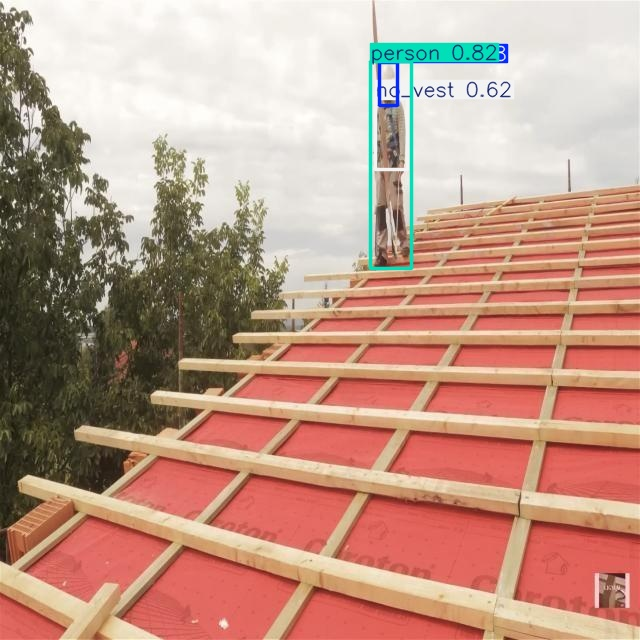

img_0069_png_jpg.rf.d139967cda66a194e523d1402f134e7b.jpg


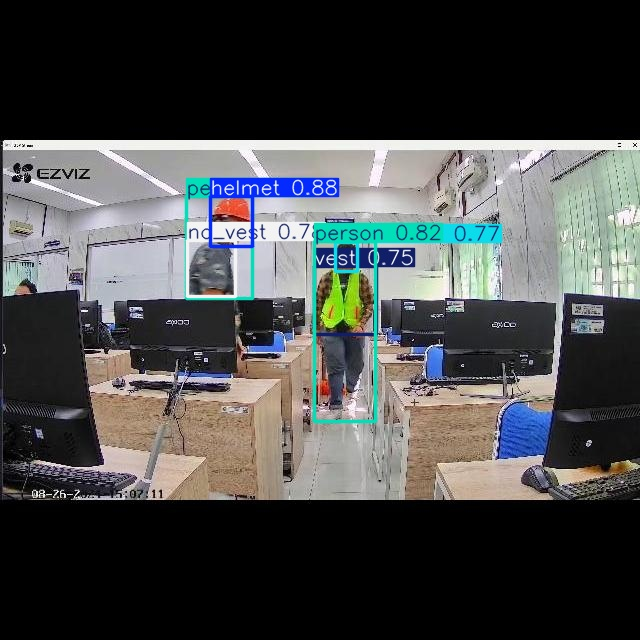

Aitin2428_jpg.rf.a3a4a16616020ba665dd36e2fdf839a6.jpg


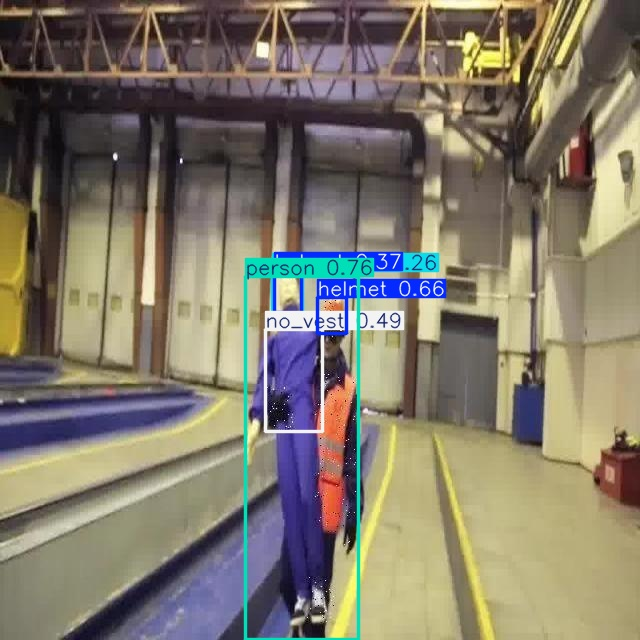

r299_jpg.rf.1e10a1a5bdfa0e1412b4c58c9c112416.jpg


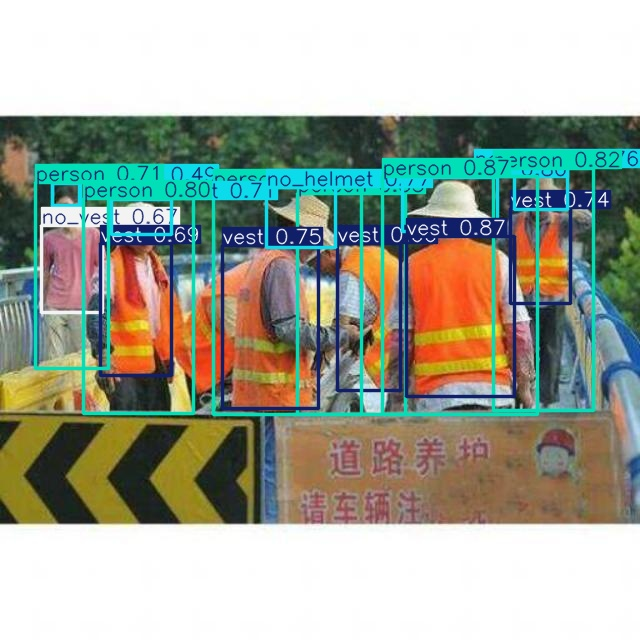

In [11]:
from PIL import Image
for f in saved[:9]:
    print(f)
    display(Image.open(f"/kaggle/working/far_vest_false_alarms/{f}"))

In [1]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 498.6 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.0 MB/s eta 0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 1.8 MB/s eta 0:00:00eta 0:00:01


In [2]:
import glob, cv2
from collections import Counter
from ultralytics import YOLO

videos = glob.glob("/kaggle/input/datasets/hamanali/secondvdtest", recursive=True) + glob.glob("/kaggle/input/**/*.mov", recursive=True)
print("Videos:", videos)
video = videos[0]

# 1. Video ki apni maloomat
cap = cv2.VideoCapture(video)
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()
print(f"FPS: {fps:.1f} | frames: {total} | size: {w}x{h} | duration: {total/fps:.1f} sec")

# 2. Model chalayein (har frame par)
model = YOLO("/kaggle/input/datasets/hamanali/bestfile/best.pt")
per_frame = []
for r in model.predict(source=video, conf=0.4, device="cpu", stream=True,
                       save=True, project="/kaggle/working/runs", name="video_test", verbose=False):
    per_frame.append(Counter(model.names[int(c)] for c in r.boxes.cls))

# 3. Khulasa
n = len(per_frame)
print(f"\nFrames processed: {n}")
for cls in ["person", "helmet", "no_helmet", "vest", "no_vest"]:
    k = sum(1 for f in per_frame if f[cls] > 0)
    print(f"{cls:10s}: {k}/{n} frames ({100*k/n:.0f}%)")

# 4. Flicker: alert kitni baar on/off hua
for cls in ["no_helmet", "no_vest"]:
    flips = sum((a[cls] > 0) != (b[cls] > 0) for a, b in zip(per_frame, per_frame[1:]))
    print(f"{cls} flicker (on/off switches): {flips}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Videos: ['/kaggle/input/datasets/hamanali/secondvdtest']


ZeroDivisionError: float division by zero

In [3]:
import os
for root, dirs, files in os.walk("/kaggle/input/datasets/hamanali/secondvdtest"):
    print(root, files)

/kaggle/input/datasets/hamanali/secondvdtest ['1012.mp4']


In [6]:
import os, cv2, time
from collections import Counter
from ultralytics import YOLO

folder = "/kaggle/input/datasets/hamanali/secondvdtest"
exts = (".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v")
videos = [os.path.join(r, f) for r, _, fs in os.walk(folder) for f in fs if f.lower().endswith(exts)]
print("Videos:", videos)
assert videos, "Koi video nahi mili"
video = videos[0]

cap = cv2.VideoCapture(video)
assert cap.isOpened(), "OpenCV video"
fps = cap.get(cv2.CAP_PROP_FPS) or 25
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS: {fps:.1f} | frames: {total} | duration: {total/fps:.1f} sec")
cap.release()

model = YOLO("/kaggle/input/datasets/hamanali/bestfile/best.pt")

os.makedirs("/kaggle/working/video_out", exist_ok=True)
out_path = "/kaggle/working/video_out/annotated_second.mp4"
writer = None
per_frame = []
t0 = time.time()

for r in model.predict(source=video, conf=0.4, device="cpu", stream=True, verbose=False):
    per_frame.append(Counter(model.names[int(c)] for c in r.boxes.cls))
    frame = r.plot(line_width=6)
    if writer is None:
        fh, fw = frame.shape[:2]
        out_w = 720
        out_h = int(fh * out_w / fw)
        writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (out_w, out_h))
    writer.write(cv2.resize(frame, (out_w, out_h)))
writer.release()

n = len(per_frame)
dt = time.time() - t0
print(f"\nFrames processed: {n} in {dt:.0f} sec ({n/dt:.1f} FPS on CPU)")
print("Persons per frame:", sorted(Counter(f["person"] for f in per_frame).items()))
for cls in ["person", "helmet", "no_helmet", "vest", "no_vest"]:
    k = sum(1 for f in per_frame if f[cls] > 0)
    print(f"{cls:10s}: {k}/{n} frames ({100*k/n:.0f}%)")

for cls in ["no_helmet", "no_vest"]:
    flips = sum((a[cls] > 0) != (b[cls] > 0) for a, b in zip(per_frame, per_frame[1:]))
    print(f"{cls} flicker (on/off switches): {flips}")

Videos: ['/kaggle/input/datasets/hamanali/secondvdtest/1012.mp4']
FPS: 30.0 | frames: 397 | duration: 13.2 sec

Frames processed: 397 in 44 sec (9.0 FPS on CPU)
Persons per frame: [(2, 367), (3, 30)]
person    : 397/397 frames (100%)
helmet    : 397/397 frames (100%)
no_helmet : 0/397 frames (0%)
vest      : 397/397 frames (100%)
no_vest   : 1/397 frames (0%)
no_helmet flicker (on/off switches): 0
no_vest flicker (on/off switches): 2


In [8]:
from collections import Counter
print("Persons per frame:", sorted(Counter(f["person"] for f in per_frame).items()))
both = sum(1 for f in per_frame if f["helmet"] >= 2 and f["vest"] >= 2)
print(f"Frames jahan helmet>=2 aur vest>=2: {both}/{len(per_frame)}")

Persons per frame: [(2, 367), (3, 30)]
Frames jahan helmet>=2 aur vest>=2: 397/397


In [11]:
from torchvision.ops import box_iou

rows = []
for i, r in enumerate(model.predict(source=video, conf=0.4, device="cpu", stream=True, verbose=False, vid_stride=5)):
    idx = [k for k, c in enumerate(r.boxes.cls.int().tolist()) if model.names[c] == "person"]
    if len(idx) >= 3:
        b, conf = r.boxes.xyxy[idx], r.boxes.conf[idx]
        iou = box_iou(b, b)
        iou.fill_diagonal_(0)
        w = int(conf.argmin())
        rows.append((i * 5, float(conf[w]), float(iou[w].max())))

print(len(rows), "sampled frames mein 3 person")
for fr, c, v in rows[:10]:
    print(f"frame {fr}: sab se kamzor person ki confidence={c:.2f}, kisi doosre person box se overlap (IoU)={v:.2f}")

5 sampled frames mein 3 person
frame 20: sab se kamzor person ki confidence=0.43, kisi doosre person box se overlap (IoU)=0.68
frame 95: sab se kamzor person ki confidence=0.70, kisi doosre person box se overlap (IoU)=0.00
frame 135: sab se kamzor person ki confidence=0.49, kisi doosre person box se overlap (IoU)=0.05
frame 240: sab se kamzor person ki confidence=0.67, kisi doosre person box se overlap (IoU)=0.69
frame 310: sab se kamzor person ki confidence=0.53, kisi doosre person box se overlap (IoU)=0.00


In [12]:
import cv2, os
os.makedirs("/kaggle/working/third_person", exist_ok=True)
saved = 0
for i, r in enumerate(model.predict(source=video, conf=0.4, device="cpu", stream=True, verbose=False, vid_stride=5)):
    cls = [model.names[c] for c in r.boxes.cls.int().tolist()]
    pidx = [k for k, c in enumerate(cls) if c == "person"]
    if len(pidx) < 3:
        continue
    conf = r.boxes.conf
    w = min(pidx, key=lambda k: float(conf[k]))
    x1, y1, x2, y2 = [int(v) for v in r.boxes.xyxy[w].tolist()]
    inside = []
    for k, c in enumerate(cls):
        if c == "person":
            continue
        bx1, by1, bx2, by2 = r.boxes.xyxy[k].tolist()
        cx, cy = (bx1 + bx2) / 2, (by1 + by2) / 2
        if x1 <= cx <= x2 and y1 <= cy <= y2:
            inside.append(c)
    img = r.orig_img.copy()
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 12)
    img = cv2.resize(img, (540, int(img.shape[0] * 540 / img.shape[1])))
    cv2.imwrite(f"/kaggle/working/third_person/frame_{i*5}.jpg", img)
    print(f"frame {i*5}: conf={float(conf[w]):.2f} | box inside : {inside}")
    saved += 1
    if saved == 4:
        break

frame 20: conf=0.43 | is box ke andar ke items: ['helmet', 'vest']
frame 95: conf=0.70 | is box ke andar ke items: []
frame 135: conf=0.49 | is box ke andar ke items: []
frame 240: conf=0.67 | is box ke andar ke items: ['vest', 'helmet']


In [10]:
import cv2, os
os.makedirs("/kaggle/working/video_out", exist_ok=True)
out_path = "/kaggle/working/video_out/annotated_big.mp4"
writer = None

for r in model.predict(source=video, conf=0.4, device="cpu", stream=True, verbose=False):
    frame = r.plot(line_width=10)            # moti lakeer, bara label
    out_w = 720
    out_h = int(frame.shape[0] * out_w / frame.shape[1])
    if writer is None:
        writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), 25, (out_w, out_h))
    writer.write(cv2.resize(frame, (out_w, out_h)))
writer.release()
print("Saved:", out_path)

Saved: /kaggle/working/video_out/annotated_big.mp4


In [3]:
!pip install -q ultralytics
import glob, os, yaml
from ultralytics import YOLO

# 1) best.pt aur dataset ka data.yaml dhoondo
best = glob.glob('/kaggle/input/**/best.pt', recursive=True)[0]
yml = [p for p in glob.glob('/kaggle/input/**/data.yaml', recursive=True)][0]
root = os.path.dirname(yml)
cfg = yaml.safe_load(open(yml))
test_dir = glob.glob(root + '/**/test/images', recursive=True)[0]
print("Model:", best)
print("Test images:", test_dir, "| count:", len(os.listdir(test_dir)))
print("Classes:", cfg['names'])

# 2) Naya yaml banao (input folder read-only hai, is liye working mein)
new_yaml = '/kaggle/working/ppe_test.yaml'
yaml.safe_dump({'train': test_dir, 'val': test_dir, 'test': test_dir,
                'names': cfg['names']}, open(new_yaml, 'w'))

# 3) Test set par model chalao (CPU)
model = YOLO(best)
m = model.val(data=new_yaml, split='test', imgsz=640, batch=16, device='cpu',
              plots=True, project='/kaggle/working/results', name='test', exist_ok=True)

# 4) Numbers text file mein save karo
out = '/kaggle/working/results/test/test_metrics.txt'
with open(out, 'w') as f:
    f.write("SafeSight AI - YOLOv8n test results (406 unseen images)\n\n")
    f.write("Class        P      R      mAP50  mAP50-95\n")
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        f.write(f"{m.names[c]:<12} {p:.3f}  {r:.3f}  {ap50:.3f}  {ap:.3f}\n")
    f.write(f"{'ALL':<12} {m.box.mp:.3f}  {m.box.mr:.3f}  {m.box.map50:.3f}  {m.box.map:.3f}\n")
print(open(out).read())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.1/47.1 kB 818.7 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 924.5 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 kB 2.3 MB/s eta 0:00:00ta 0:00:01
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model: /kaggle/input/datasets/hamanali/bestfile/best.pt
Test images: /kaggle/input/datasets/tafartech/personal-protective-equipmentppe/Personal-Protective-Equipment (PPE) Dataset/test/images | count: 406
Classes: ['helmet', 'no_helmet', 'no_vest', 'person', 'vest']
Ultralytics 8.4.195 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model 

In [1]:
import os
print(os.path.exists("/kaggle/working/video_out/annotated_big.mp4"))

False


In [2]:
!ls /kaggle/working/runs/detect/

ls: cannot access '/kaggle/working/runs/detect/': No such file or directory


In [4]:
!ls /kaggle/working/results/test/
!cd /kaggle/working && zip -r safesight_test_results.zip results/test

BoxF1_curve.png			 confusion_matrix.png	val_batch1_pred.jpg
BoxP_curve.png			 test_metrics.txt	val_batch2_labels.jpg
BoxPR_curve.png			 val_batch0_labels.jpg	val_batch2_pred.jpg
BoxR_curve.png			 val_batch0_pred.jpg
confusion_matrix_normalized.png  val_batch1_labels.jpg
  adding: results/test/ (stored 0%)
  adding: results/test/val_batch1_labels.jpg (deflated 5%)
  adding: results/test/test_metrics.txt (deflated 45%)
  adding: results/test/val_batch0_labels.jpg (deflated 14%)
  adding: results/test/val_batch1_pred.jpg (deflated 5%)
  adding: results/test/val_batch2_labels.jpg (deflated 7%)
  adding: results/test/BoxPR_curve.png (deflated 11%)
  adding: results/test/val_batch0_pred.jpg (deflated 14%)
  adding: results/test/BoxR_curve.png (deflated 9%)
  adding: results/test/confusion_matrix_normalized.png (deflated 21%)
  adding: results/test/confusion_matrix.png (deflated 22%)
  adding: results/test/BoxF1_curve.png (deflated 8%)
  adding: results/test/BoxP_curve.png (deflated 10%)
  ad